---
title: "3.1.c Riesgo por inundación fluvial"
short_title: "c. Riesgo"
subtitle: "Edificaciones y personas expuestas, daño esperado y zonas bajas de la ciudad"
description: "Cruce de la amenaza por creciente del Amazonas con edificaciones y población de Leticia; daño esperado y pérdida anual esperada."
keywords: [inundación, exposición, daño, pérdida anual esperada, HAND, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/31_inundacion/c_riesgo.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El riesgo resulta de cruzar la amenaza (profundidad para cada periodo de retorno) con la exposición
(edificaciones y población de [2.6](../../02_datos/26_area_estudio.ipynb)) y una función de vulnerabilidad
(curva profundidad–daño). El procedimiento sigue la evaluación espacial del impacto de CCDR-tools
[@amadio2024ccdr]: intersección, fracción de daño e integración sobre la curva de excedencia.

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import aoi, espacial, exposicion, fuentes, riesgo, viz
from leticia.config import parametros

p = parametros()["inundacion"]
edif = exposicion.edificaciones_urbanas()
malla = exposicion.malla_exposicion()
pts = edif.representative_point().to_crs(4326)

## 1. Exposición por periodo de retorno

In [3]:
filas, prof_por_rp = [], {}
for rp in p["periodos_jrc"]:
    d = fuentes.inundacion_jrc(rp)
    prof = np.nan_to_num(d.interp(x=("p", pts.x.values), y=("p", pts.y.values), method="nearest").values)
    prof_por_rp[rp] = prof
    expuesta = prof >= p["profundidad_minima_m"]
    danio = riesgo.fraccion_danio(prof) * edif["area_m2"].values * p["costo_reposicion_cop_m2"]
    filas.append({"periodo_retorno": rp, "edificaciones": int(expuesta.sum()), "personas": edif.loc[expuesta, "poblacion"].sum(),
                  "profundidad_media_m": prof[expuesta].mean() if expuesta.any() else 0, "danio_mm_cop": danio.sum() / 1e6})
tabla = pd.DataFrame(filas).set_index("periodo_retorno")
display(tabla.round({"personas": 0, "profundidad_media_m": 2, "danio_mm_cop": 0}))

,edificaciones,personas,profundidad_media_m,danio_mm_cop
periodo_retorno,,,,
10,1240,"3,850.00",3.95,"215,956.00"
20,1452,"4,445.00",4.33,"265,979.00"
50,1630,"4,948.00",4.82,"306,577.00"
100,1744,"5,456.00",5.18,"335,486.00"
200,1919,"6,021.00",5.32,"365,976.00"
500,2453,"8,515.00",5.30,"484,331.00"


In [4]:
pae = riesgo.perdida_anual_esperada(tabla["danio_mm_cop"])
eae = riesgo.perdida_anual_esperada(tabla["personas"])
display(Markdown(f"**Pérdida anual esperada (daño directo a edificaciones):** ≈ {pae:,.0f} millones de COP/año. "
                 f"**Población expuesta anual esperada:** ≈ {eae:,.0f} personas/año. "
                 "Ambas cifras dependen del costo de reposición ilustrativo de `parametros.yaml` y de la resolución de 90 m del JRC.".replace(",", ".")))

**Pérdida anual esperada (daño directo a edificaciones):** ≈ 37.674 millones de COP/año. **Población expuesta anual esperada:** ≈ 643 personas/año. Ambas cifras dependen del costo de reposición ilustrativo de `parametros.yaml` y de la resolución de 90 m del JRC.

:::{important} Cómo leer estas cifras
El modelo global del JRC no conoce los rellenos, el malecón ni las viviendas palafíticas, y su resolución de
90 m mezcla en una sola celda la orilla y la terraza. Las cifras son un **orden de magnitud** para comparar
amenazas, no un inventario de daños. El costo de reposición es ilustrativo.
:::

## 2. Altura sobre el río: dónde están las zonas bajas

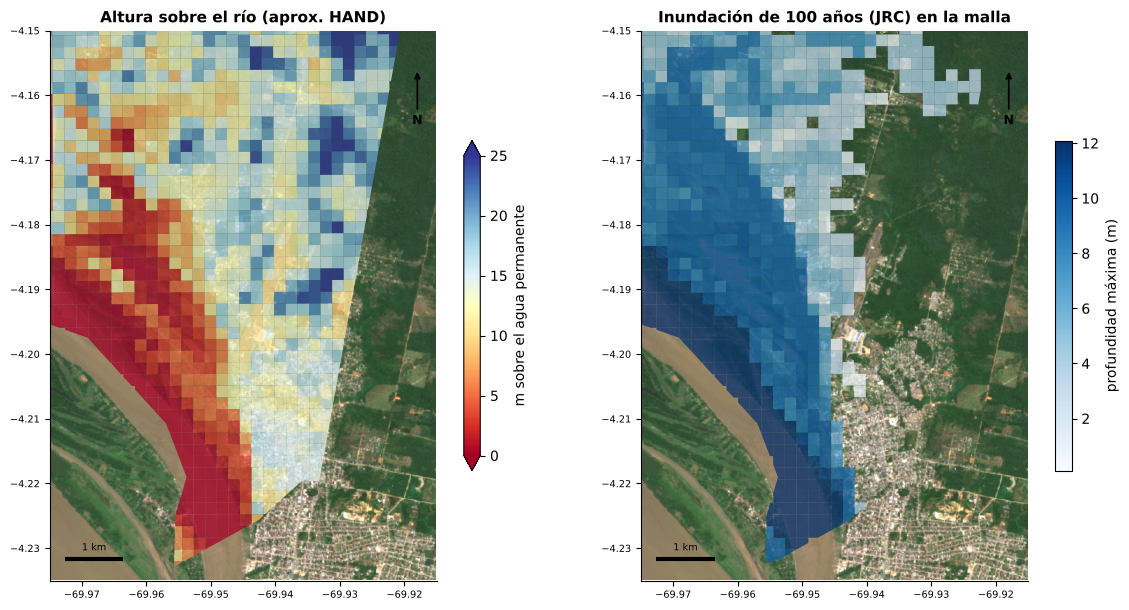

In [5]:
dem = fuentes.raster_estatico("cop-dem-glo-30", "data")
occ = fuentes.raster_estatico("jrc-gsw", "occurrence")
agua_perm = occ >= 90
hand = espacial.altura_sobre_agua(dem, agua_perm)
malla["hand_m"] = espacial.estadistica_zonal(hand, malla, "mean")
malla["prof_rp100_m"] = espacial.estadistica_zonal(fuentes.inundacion_jrc(100).fillna(0), malla, "max")
fig, ax = plt.subplots(1, 2, figsize=(12, 6.2))
viz.mapa_celdas(malla, "hand_m", ax=ax[0], cmap="RdYlBu", etiqueta="m sobre el agua permanente", vmin=0, vmax=25,
                titulo="Altura sobre el río (aprox. HAND)")
viz.mapa_celdas(malla[malla.prof_rp100_m > 0], "prof_rp100_m", ax=ax[1], cmap="Blues", etiqueta="profundidad máxima (m)",
                titulo="Inundación de 100 años (JRC) en la malla")
fig.tight_layout()

In [6]:
viz.pie(viz.nota_fuente("elevacion", "agua_superficial_jrc", "inundacion_jrc"))

*Fuente: Copernicus DEM GLO-30 — DSM 30 m (TanDEM-X 2011–2015); JRC – Global Surface Water (Pekel et al. 2016) — occurrence, seasonality, transitions, extent; JRC – Copernicus EMS (GloFAS) — Global river flood hazard maps v2.1 (RP10–RP500), LISFLOOD-FP.*

La **altura sobre el río** compara la elevación de cada lugar con la del agua permanente más cercana
[@renno2008hand]. Como el modelo de superficie incluye árboles y techos, sobreestima la altura en zonas
arboladas; aun así ordena bien los barrios: los valores bajos señalan la franja ribereña y los fondos de
quebrada, que una creciente extraordinaria alcanza primero.

## 3. Sensibilidad: ¿qué pasa si el río sube más?

altura_m,0.00,2.00,4.00,6.00,8.00,10.00,12.00,14.00
edificaciones,120,135,288,590,695,914,2023,4101
personas,519,521,883,2061,2753,3853,8595,22162


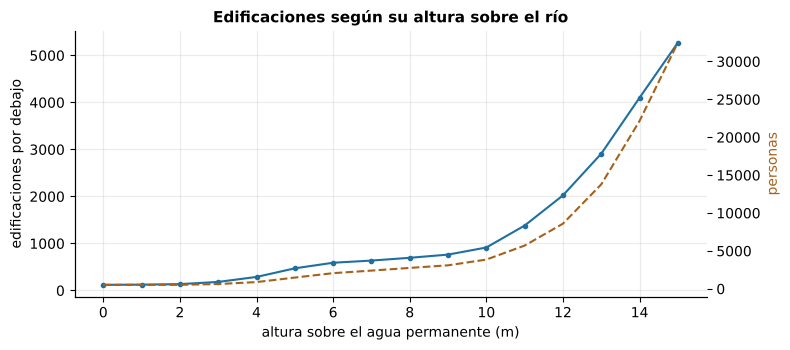

In [7]:
edif_hand = np.nan_to_num(hand.interp(x=("p", pts.x.values), y=("p", pts.y.values), method="nearest").values, nan=99)
umbrales = np.arange(0, 16, 1.0)
curva = pd.DataFrame({"altura_m": umbrales,
                      "edificaciones": [(edif_hand <= h).sum() for h in umbrales],
                      "personas": [edif.loc[edif_hand <= h, "poblacion"].sum() for h in umbrales]}).set_index("altura_m")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva.index, curva["edificaciones"], color=viz.AZUL_RIO, marker="o", ms=3)
ax.set_xlabel("altura sobre el agua permanente (m)")
ax.set_ylabel("edificaciones por debajo")
ax.set_title("Edificaciones según su altura sobre el río")
ax2 = ax.twinx()
ax2.plot(curva.index, curva["personas"], color=viz.TIERRA, ls="--")
ax2.set_ylabel("personas", color=viz.TIERRA)
ax2.grid(False)
fig.tight_layout()
display(curva.iloc[::2].round(0).astype(int).T)

**Lectura.** La curva muestra cuánto crece la exposición por cada metro adicional de agua sobre el nivel de
referencia del agua permanente. Es la forma más directa de traducir los escenarios de la sección d —crecientes
más altas por intensificación del ciclo hidrológico— en edificaciones y personas.

## 4. Clases de riesgo por celda

,n_edif,poblacion
riesgo_inundacion,,
Muy baja,357,"2,866.00"
Baja,4457,"35,750.00"
Media,1129,"4,773.00"
Alta,669,"2,240.00"
Muy alta,196,877.00


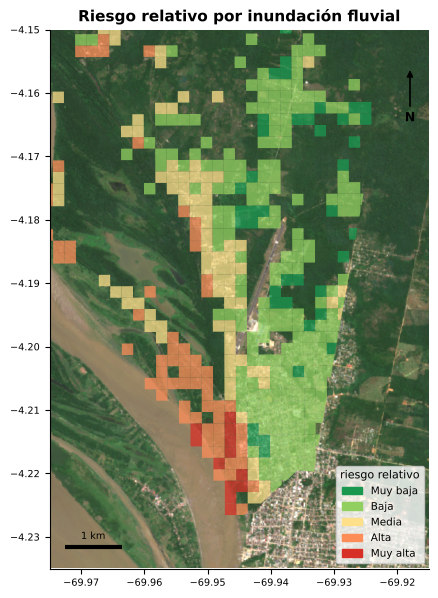

In [8]:
malla["dist_rio_m"] = espacial.distancia_a(malla, espacial.vectorizar(agua_perm.rio.write_crs(4326), 200))
lst = espacial.temperatura_superficie(2024, parametros()["calor"]["meses_landsat"])
malla["ndvi"] = espacial.estadistica_zonal(lst["ndvi"].rio.write_crs(4326), malla)
malla["vulnerabilidad"] = riesgo.indice_vulnerabilidad(malla)
# amenaza: profundidad de 100 años y altura sobre el río (más bajo = más amenaza)
amenaza_idx = 0.5 * riesgo.normalizar(malla["prof_rp100_m"].fillna(0)) + 0.5 * riesgo.normalizar(malla["hand_m"], invertir=True)
malla["amenaza_clase"] = riesgo.clasificar(amenaza_idx)
malla["vuln_clase"] = riesgo.clasificar(malla["vulnerabilidad"])
malla["riesgo_inundacion"] = riesgo.matriz_riesgo(malla["amenaza_clase"], malla["vuln_clase"])
con_edif = malla[malla.n_edif > 0]
fig, ax = plt.subplots(figsize=(6.4, 7))
viz.mapa_celdas(con_edif, "riesgo_inundacion", ax=ax, categorias=riesgo.CLASES, colores=riesgo.COLORES_CLASES,
                etiqueta="riesgo relativo", titulo="Riesgo relativo por inundación fluvial")
resumen = con_edif.groupby("riesgo_inundacion", observed=False)[["n_edif", "poblacion"]].sum().round(0)
display(resumen)
malla[["hand_m", "prof_rp100_m", "dist_rio_m", "ndvi", "vulnerabilidad", "riesgo_inundacion"]].to_csv(fuentes.ruta("riesgo_inundacion_celdas.csv"))

Las clases son **relativas dentro de Leticia** (quintiles), no absolutas. La amenaza combina la profundidad
del JRC y la altura sobre el río; la vulnerabilidad, la densidad construida, la población, la cercanía al río y
la falta de vegetación (pesos en `parametros.yaml`). La tabla de celdas queda guardada para la síntesis
([3.7](../37_sintesis.ipynb)).